# 5. Modal decomposition

The free linear model $dx'/dt=\mathbf{A}x'$ is governed entirely by the operator
$\mathbf{A}$. Its **eigenmodes** $\mathbf{A}\phi=\lambda\phi$ are the
self-sustaining patterns: $\operatorname{Re}\lambda$ is a growth rate and
$\operatorname{Im}\lambda$ a frequency. This chapter extracts them for the full
primitive-equation operator and shows they describe **baroclinic instability** —
the engine of extratropical weather (WK guide §5.1–5.2).

The full operator is far too large to diagonalise, but a **zonally-symmetric**
basic state makes it block-diagonal in zonal wavenumber $m$, so each
$\mathbf{A}_m$ is a small dense matrix for `numpy.linalg.eig`. Eigenvalues are
**norm-independent**, so they are clean even though the primitive equations carry
fast gravity waves; the *optimal-vector* (singular-vector) analysis of WK §5.3,
which needs a physical energy norm, is done in the gravity-wave-free
[](08-barotropic.ipynb), where it is unambiguous.

:::{note} Operator for modal analysis
Eigen-analysis uses the operator with a **small read-out time step** (`dt=100` s),
so `(step − I)/2dt` approximates the *continuous* tendency $\mathbf{L}$, and with
**hyperdiffusion only** (`lt.no_damping_config()` + $\nabla^4$) so the fast
gravity-wave / grid noise is damped while the baroclinic modes are untouched.
:::

In [1]:
import os, sys, warnings
warnings.filterwarnings("ignore")
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")
root = os.path.abspath("")
while root != os.path.dirname(root) and not os.path.isdir(os.path.join(root, "pylbm_isca")):
    root = os.path.dirname(root)
sys.path.insert(0, root)
sys.path.insert(0, os.path.join(root, "docs", "book"))
import numpy as np
import matplotlib.pyplot as plt
from pylbm_isca import Config, LBM, Spectral, VerticalGrid
from pylbm_isca.backend import asnumpy, gpu_available
import lbmtools as lt

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(nlon=64, nlat=32, nmax=21, device=DEVICE)   # T21 L20, runs offline
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = sp.lon_deg, sp.lat_deg, asnumpy(vg.sig)
print(f"PyLBM-Isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

PyLBM-Isca  T21  64x32  L20  backend=gpu


## 5.1 Eigenvalue analysis

A mid-latitude **baroclinic jet**, symmetrised in longitude. We build one zonal
wavenumber block $\mathbf{A}_6$ and diagonalise it.

In [2]:
from numpy.linalg import eig

def hdif_only(tefold_h=6.0):
    c = lt.no_damping_config()
    c.hdif_order, c.hdif_tefold, c.hdif_tunit = 4, tefold_h, "HOUR"
    return c

m = 6
jet = lt.baroclinic_jet(sp, vg, umax=35.0, dtdy=60.0)
zbs = lt.zonal_mean(jet)                                # zonally symmetric
tl  = lt.TangentLinear(sp, vg, zbs, cfg=hdif_only(), mvals=[m], dt=100.0)
A   = tl.dense()
w, V = eig(A)
growth = w.real * 86400.0                               # day^-1
period = np.where(np.abs(w.imag) > 0, 2*np.pi/np.abs(w.imag)/86400.0, np.inf)
j = int(np.argmax(growth))                              # leading mode
print(f"block m={m}, size {tl.size}")
print(f"leading eigenmode: growth {growth[j]:+.3f} /day, "
      f"period {period[j]:.1f} day, {int((growth>1e-3).sum())} unstable modes")

block m=6, size 1296
leading eigenmode: growth +0.244 /day, period 12.6 day, 6 unstable modes


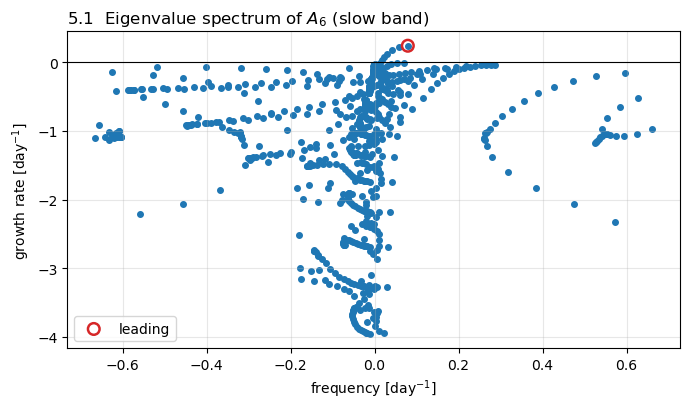

Modes above the black line grow: the operator is baroclinically unstable.


In [3]:
keep = period > 1.5                                     # focus on the slow band
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(1.0/period[keep]*np.sign(w.imag[keep]), growth[keep], s=16, c="C0")
ax.scatter([1.0/period[j]*np.sign(w.imag[j])], [growth[j]], s=70,
           facecolors="none", edgecolors="C3", linewidths=1.8, label="leading")
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("frequency [day$^{-1}$]"); ax.set_ylabel("growth rate [day$^{-1}$]")
ax.set_title(f"5.1  Eigenvalue spectrum of $A_{{{m}}}$ (slow band)", loc="left")
ax.legend(); ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
print("Modes above the black line grow: the operator is baroclinically unstable.")

## 5.2 It is baroclinic instability

The instability is driven by the basic-state **meridional temperature gradient**
(available potential energy). Increasing that gradient `dtdy` while holding
everything else fixed raises the growth rate and, past a threshold, turns a
damped operator unstable — the defining behaviour of baroclinic instability.

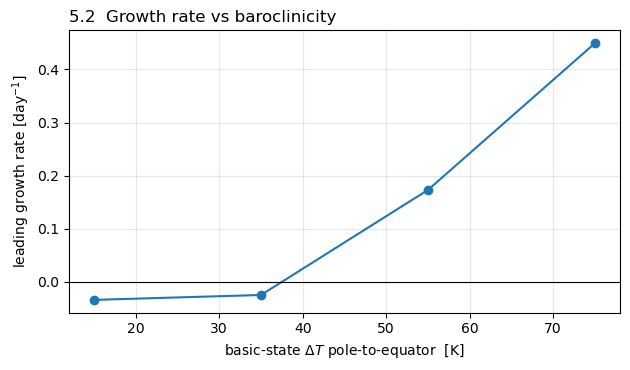

Growth increases monotonically with the temperature gradient and changes sign at a critical baroclinicity -- the baroclinic instability threshold.


In [4]:
dtdys = [15.0, 35.0, 55.0, 75.0]
lead = []
for g in dtdys:
    z = lt.zonal_mean(lt.baroclinic_jet(sp, vg, umax=35.0, dtdy=g))
    tlg = lt.TangentLinear(sp, vg, z, cfg=hdif_only(), mvals=[m], dt=100.0)
    lead.append(np.linalg.eigvals(tlg.dense()).real.max()*86400.0)
fig, ax = plt.subplots(figsize=(6.4, 3.8))
ax.plot(dtdys, lead, "o-"); ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel(r"basic-state $\Delta T$ pole-to-equator  [K]")
ax.set_ylabel("leading growth rate [day$^{-1}$]")
ax.set_title("5.2  Growth rate vs baroclinicity", loc="left")
ax.grid(alpha=0.3); fig.tight_layout(); plt.show()
print("Growth increases monotonically with the temperature gradient and changes "
      "sign at a critical baroclinicity -- the baroclinic instability threshold.")

## 5.3 Structure of the leading mode, and preferred modes under damping

The leading eigenvector is the fastest-growing baroclinic wave. Shown as a
longitude–height section of $T'$ at the jet latitude, it has the characteristic
**upshear (westward-with-height) tilt** that converts basic-state available
potential energy into eddy energy.

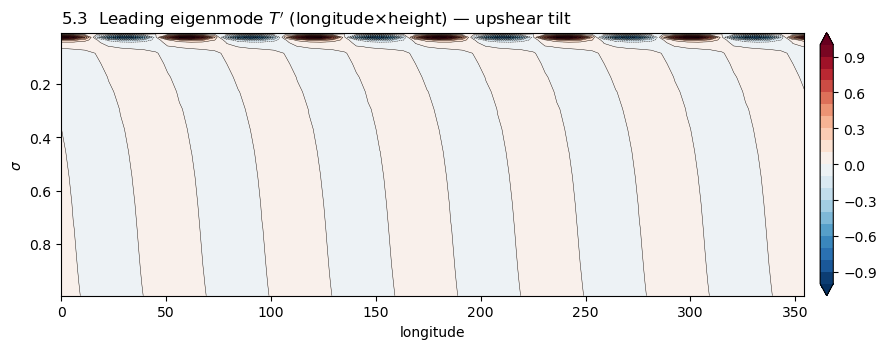

In [5]:
st = tl.to_state(np.ascontiguousarray(V[:, j]))
Tg = asnumpy(st.t).real
jlat = int(np.argmin(np.abs(lat - 45.0)))
sec = Tg[jlat].T                                        # (sigma, lon)
# normalise and roll so the pattern is centred
sec = sec / (np.abs(sec).max() or 1.0)
v = 1.0
fig, ax = plt.subplots(figsize=(9, 3.6))
cf = ax.contourf(lon, sig, sec, levels=np.linspace(-v, v, 21), cmap="RdBu_r",
                 extend="both")
ax.contour(lon, sig, sec, levels=np.linspace(-v, v, 21), colors="k",
           linewidths=0.3)
ax.set_ylim(sig.max(), sig.min()); ax.set_xlabel("longitude")
ax.set_ylabel(r"$\sigma$")
ax.set_title(r"5.3  Leading eigenmode $T'$ (longitude$\times$height) — "
             r"upshear tilt", loc="left")
fig.colorbar(cf, ax=ax, pad=0.02, fraction=0.03); fig.tight_layout(); plt.show()

In [6]:
# With realistic dissipation every mode decays; the LEAST-damped is the
# 'preferred mode' the system relaxes onto last (WK guide s5.1).
from pylbm_isca import Config
tl_d = lt.TangentLinear(sp, vg, zbs, cfg=Config(), mvals=[m], dt=100.0)
wd = np.linalg.eigvals(tl_d.dense())
jd = int(np.argmax(wd.real))
pd = 2*np.pi/abs(wd[jd].imag)/86400.0 if abs(wd[jd].imag) > 0 else np.inf
print(f"with realistic damping: least-damped mode decays at "
      f"{-wd[jd].real*86400:.3f}/day, period {pd:.1f} day "
      "(the 'preferred mode').")

with realistic damping: least-damped mode decays at 0.103/day, period 1184.3 day (the 'preferred mode').


### Summary

| step | operation on $\mathbf{A}_m$ | result |
|---|---|---|
| eigenvalues (§5.1) | `numpy.linalg.eig` | growth rate + frequency of every free mode |
| instability (§5.2) | leading $\operatorname{Re}\lambda$ vs $\Delta T$ | the baroclinic-instability threshold |
| structure (§5.3) | leading eigenvector | the upshear-tilted growing wave; and, under damping, the least-damped *preferred* mode |

All come from the same dense block $\mathbf{A}_m$ — the tractable route to the
full-operator modal analysis. The companion **optimal-growth / singular-vector**
analysis (WK §5.3), which needs a physical energy norm that the fast gravity
waves make delicate here, is carried out cleanly in the gravity-wave-free
[](08-barotropic.ipynb).